In [1]:
#collect all time points for one cancer type and perform clustering analysis

# libraries

In [2]:
import patientClassFunctions as ptfn
import numpy as np
import pandas as pd
import matplotlib as mpl
import seaborn as sns
import os
# import seaborn as sns
from sklearn.decomposition import PCA
import umap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

c:\Users\maega\anaconda3\envs\BeatCancerLab\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from sklearn.neighbors import NearestNeighbors
import networkx as nx
from scipy import sparse
from community import community_louvain
import community
from collections import defaultdict
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.metrics import mutual_info_score, adjusted_rand_score

# directory management

In [4]:
computer_path_header = "C:\\Users\\maega"
# computer_path_header = "C:\\Users\\mcremer"
folder_path2= "UFL Dropbox\\Maegan Cremer\\BTO-data"
folder_path_processed = "012_Processed_Data"
path_ptdata = os.path.join(computer_path_header, folder_path2, folder_path_processed, "patient_files")
os.chdir(path_ptdata)

# file importing and patient class

In [5]:
#importing patient data as dictionaries of dataframes

#build a dictionary of patients and their values 
ptFiles = ptfn.GetListofPTfiles(path_ptdata, '.xlsx', 'BTO')

ptDict = {}

#loop through the listOfPatients 
for file in ptFiles: 
    pt = ptfn.patient(path_ptdata, file, 7)
    ptDict[pt.ptID] = pt

BTO-002 no patient identifying information
BTO-051 no patient identifying information
BTO-081 no patient identifying information


# collecting the data

In [6]:
#the primary tumor type of interest
#1, Esophagogastric | 2, HCC | 3, Biliary Tract | 4, Pancreatic | 5, Colorectal | 6, Anal | 7, NET | 8, Other GI cancer
primaryOfinterest = 4 #some integer as described above

In [7]:
# test_primary = {}
methylationDict = {}
RedCapDict = {}

primarytumorEnrollementDict = {}

metEnrollmentDict = {}
metEnrollmentPresence = {}
tumortypeDict = {} #cancer type

NSRdict = {} #time is real dates, to align we need to know what the baseline is in the RECIST
recistDict = {} #the met sites vs time per radiology. time is in days since some baseline scan
recistLocsNames = {} #the names of the met sites per radiology

BTOclinicalDict = {} #this containes SOD and some treatment information

for ptID in ptDict.keys():
    ptdata = ptDict[ptID]
    if ptdata.methylationSignatures is not False and ptdata.ptDemographics is not False:
            if len(ptdata.NSR)>2: #filter for those with 3 or more measures
                RedCapDict[ptID] = ptdata.ptDemographics #all redcap data not just demographics
                methylationDict[ptID] = ptdata.methylationSignatures #all time points
                tumortypeDict[ptID] = ptdata.primarytumor #numeric code for type of primary tumor
                primarytumorEnrollementDict[ptID]= ptdata.primarytumorEnrollment #binary if primary tumor is present at enrollment
                metEnrollmentDict[ptID] = ptdata.metEnrollmentList #numeric list of locations of mets at enrollment 
                metEnrollmentPresence[ptID] = ptdata.metsAtEnrollment #length of met sites
                NSRdict[ptID] = ptdata.NSR
                recistDict[ptID] = ptdata.RECIST_vtime #the temporal information about met locations and sizes
                recistLocsNames[ptID] = ptdata.RECIST_locs
                BTOclinicalDict[ptID] = ptdata.BTOClinical

print(len(methylationDict.keys()))

75


In [8]:
BTOclinicalDict.keys()

dict_keys(['BTO-006', 'BTO-007', 'BTO-008', 'BTO-009', 'BTO-010', 'BTO-011', 'BTO-013', 'BTO-016', 'BTO-018', 'BTO-019', 'BTO-022', 'BTO-025', 'BTO-026', 'BTO-027', 'BTO-030', 'BTO-031', 'BTO-032', 'BTO-033', 'BTO-034', 'BTO-035', 'BTO-038', 'BTO-039', 'BTO-040', 'BTO-041', 'BTO-042', 'BTO-043', 'BTO-044', 'BTO-047', 'BTO-048', 'BTO-049', 'BTO-052', 'BTO-053', 'BTO-055', 'BTO-056', 'BTO-059', 'BTO-061', 'BTO-062', 'BTO-072', 'BTO-073', 'BTO-074', 'BTO-076', 'BTO-077', 'BTO-078', 'BTO-079', 'BTO-080', 'BTO-083', 'BTO-084', 'BTO-086', 'BTO-088', 'BTO-089', 'BTO-091', 'BTO-092', 'BTO-093', 'BTO-097', 'BTO-098', 'BTO-099', 'BTO-101', 'BTO-102', 'BTO-104', 'BTO-108', 'BTO-109', 'BTO-110', 'BTO-111', 'BTO-113', 'BTO-114', 'BTO-117', 'BTO-120', 'BTO-122', 'BTO-125', 'BTO-128', 'BTO-129', 'BTO-130', 'BTO-131', 'BTO-132', 'BTO-134'])

In [9]:
BTOclinicalDict['BTO-092']

,patient_id,patient_id.1,requisition_id,collection_number,mRECIST,TMS,TMS_LOG10,call_baseline,call_prior,sex,...,collection_days,Current Tx Start - Baseline Blood Draw (Days),baseline_volume,response1_volume,response2_volume,response3_volume,response4_volume,response5_volume,evaluable_status,Non_RECIST/Clinical_calls
0,BTO-092,BTO-092,NaN,1,NaN,NaN,NaN,NaN,NaN,Male,...,0,0,351300,NaN,NaN,NaN,NaN,NaN,Evaluable,1
1,BTO-092,BTO-092,NaN,2,NaN,NaN,NaN,NaN,NaN,Male,...,14,0,351300,NaN,NaN,NaN,NaN,NaN,Evaluable,1
2,BTO-092,BTO-092,NaN,3,NaN,NaN,NaN,NaN,NaN,Male,...,31,0,351300,NaN,NaN,NaN,NaN,NaN,Evaluable,1
3,BTO-092,BTO-092,NaN,4,NaN,NaN,NaN,NaN,NaN,Male,...,45,0,351300,NaN,NaN,NaN,NaN,NaN,Evaluable,1


## handling time

In [10]:
#List of patients that have both radiology measures and metheylation patterns
listPts = [ptID for ptID in methylationDict.keys() if recistDict[ptID] is not False]
len(listPts)

74

In [ ]:
#example patient to parameterize some lists
ptID = 'BTO-018'

ptRedCapData = RedCapDict[ptID]

#columns of interest with time information 
RedCapTimeCols = [col for col in ptRedCapData.columns if 'date_' in col] #"radiology_date_v4", 'biomarker_date_v1'

#must convert one column at a time, handles the missign data well
for col in RedCapTimeCols: 
    ptRedCapData[col] = pd.to_datetime(ptRedCapData[col]) #in place replacement for the time columns

In [ ]:
#collecting radiological time for patients from redCap data to align with RECIST, uses the example patient
radTimeCols = [col for col in RedCapTimeCols if 'radiology' in col]
TMStimeCols = [col for col in RedCapTimeCols if 'biomarker' in col] #this corresponds to the NSR dates
ptRedCapData[TMStimeCols]

Unnamed: 0,biomarker_date_v1,biomarker_date_v2,biomarker_date_v3,biomarker_date_v4,biomarker_date_v5,biomarker_date_v6,biomarker_date_v7,biomarker_date_v8,biomarker_date_v9,biomarker_date_v10,biomarker_date_v11,biomarker_date_v12
0,2023-07-17,2023-07-31,2023-08-14,2023-08-28,2023-09-08,NaT,NaT,NaT,NaT,NaT,NaT,NaT


In [ ]:
# ptRedCapData[radTimeCols].T.values

array([['2023-07-17T00:00:00.000000000'],
       ['2023-09-10T00:00:00.000000000'],
       [                          'NaT'],
       [                          'NaT'],
       [                          'NaT'],
       [                          'NaT'],
       [                          'NaT']], dtype='datetime64[ns]')

In [ ]:
#NSR time information 'collection_date', checking that the biomarker dates correlated with NSR dates
ptID = 'BTO-018'

ptData_NSR = NSRdict[ptID]

#columns of interest with time information 
NSRTimeCols = ['collection_date'] 

ptDataTime_NSR = pd.to_datetime(ptData_NSR['collection_date'])
ptDataTime_NSR

0   2023-07-17
1   2023-07-31
2   2023-08-14
3   2023-08-28
Name: collection_date, dtype: datetime64[ns]

In [18]:
for ptID in listPts:
    #RECIST data 
    ptRECIST_data = recistDict[ptID]
    ptRedCapData = RedCapDict[ptID]
    ptData_NSR = NSRdict[ptID]

    if ptRECIST_data is not False: #some patients don't have RECIST information right now
   
        #add a new time column that is the biomarker_date column from the redcap 
        ptRECIST_data['date'] = ptRECIST_data['Days to ']

        #convert to time
        for col in RedCapTimeCols: 
            ptRedCapData[col] = pd.to_datetime(ptRedCapData[col]) #in place replacement for the time columns
            
        #connect the redcap and recist data together for time type in its own column
        for instance in range(len(ptRECIST_data['Days to '])): 
            ptRECIST_data['date'][instance]= ptRedCapData[radTimeCols].T.iat[instance,0]

        recistDict[ptID] = ptRECIST_data

    if ptData_NSR is not False:
        ptDataTime_NSR['collection_date'] = pd.to_datetime(ptData_NSR['collection_date'])
        NSRdict[ptID] = ptDataTime_NSR #updates the dictionary to use the time information 

C:\Users\maega\AppData\Local\Temp\ipykernel_17440\3851082052.py:18: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  ptRECIST_data['date'][instance]= ptRedCapData[radTimeCols].T.iat[instance,0]
C:\Users\maega\AppData\Local\Temp\ipykernel_17440\

In [19]:
#BTO clincial data time column 
BTOclinicalDict['BTO-018']

,patient_id,patient_id.1,requisition_id,collection_number,mRECIST,TMS,TMS_LOG10,call_baseline,call_prior,sex,...,collection_days,Current Tx Start - Baseline Blood Draw (Days),baseline_volume,response1_volume,response2_volume,response3_volume,response4_volume,response5_volume,evaluable_status,Non_RECIST/Clinical_calls
0,BTO-018,BTO-018,NaN,1,NaN,NaN,NaN,NaN,NaN,Male,...,0,0,3378.2,3348.3,NaN,NaN,NaN,NaN,Evaluable,0
1,BTO-018,BTO-018,NaN,2,NaN,NaN,NaN,NaN,NaN,Male,...,14,0,3378.2,3348.3,NaN,NaN,NaN,NaN,Evaluable,0
2,BTO-018,BTO-018,NaN,3,NaN,NaN,NaN,NaN,NaN,Male,...,28,0,3378.2,3348.3,NaN,NaN,NaN,NaN,Evaluable,0
3,BTO-018,BTO-018,NaN,4,NaN,NaN,NaN,NaN,NaN,Male,...,42,0,3378.2,3348.3,NaN,NaN,NaN,NaN,Evaluable,0


## event plot

C:\Users\maega\AppData\Local\Temp\ipykernel_37180\1864876510.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab10', 8)


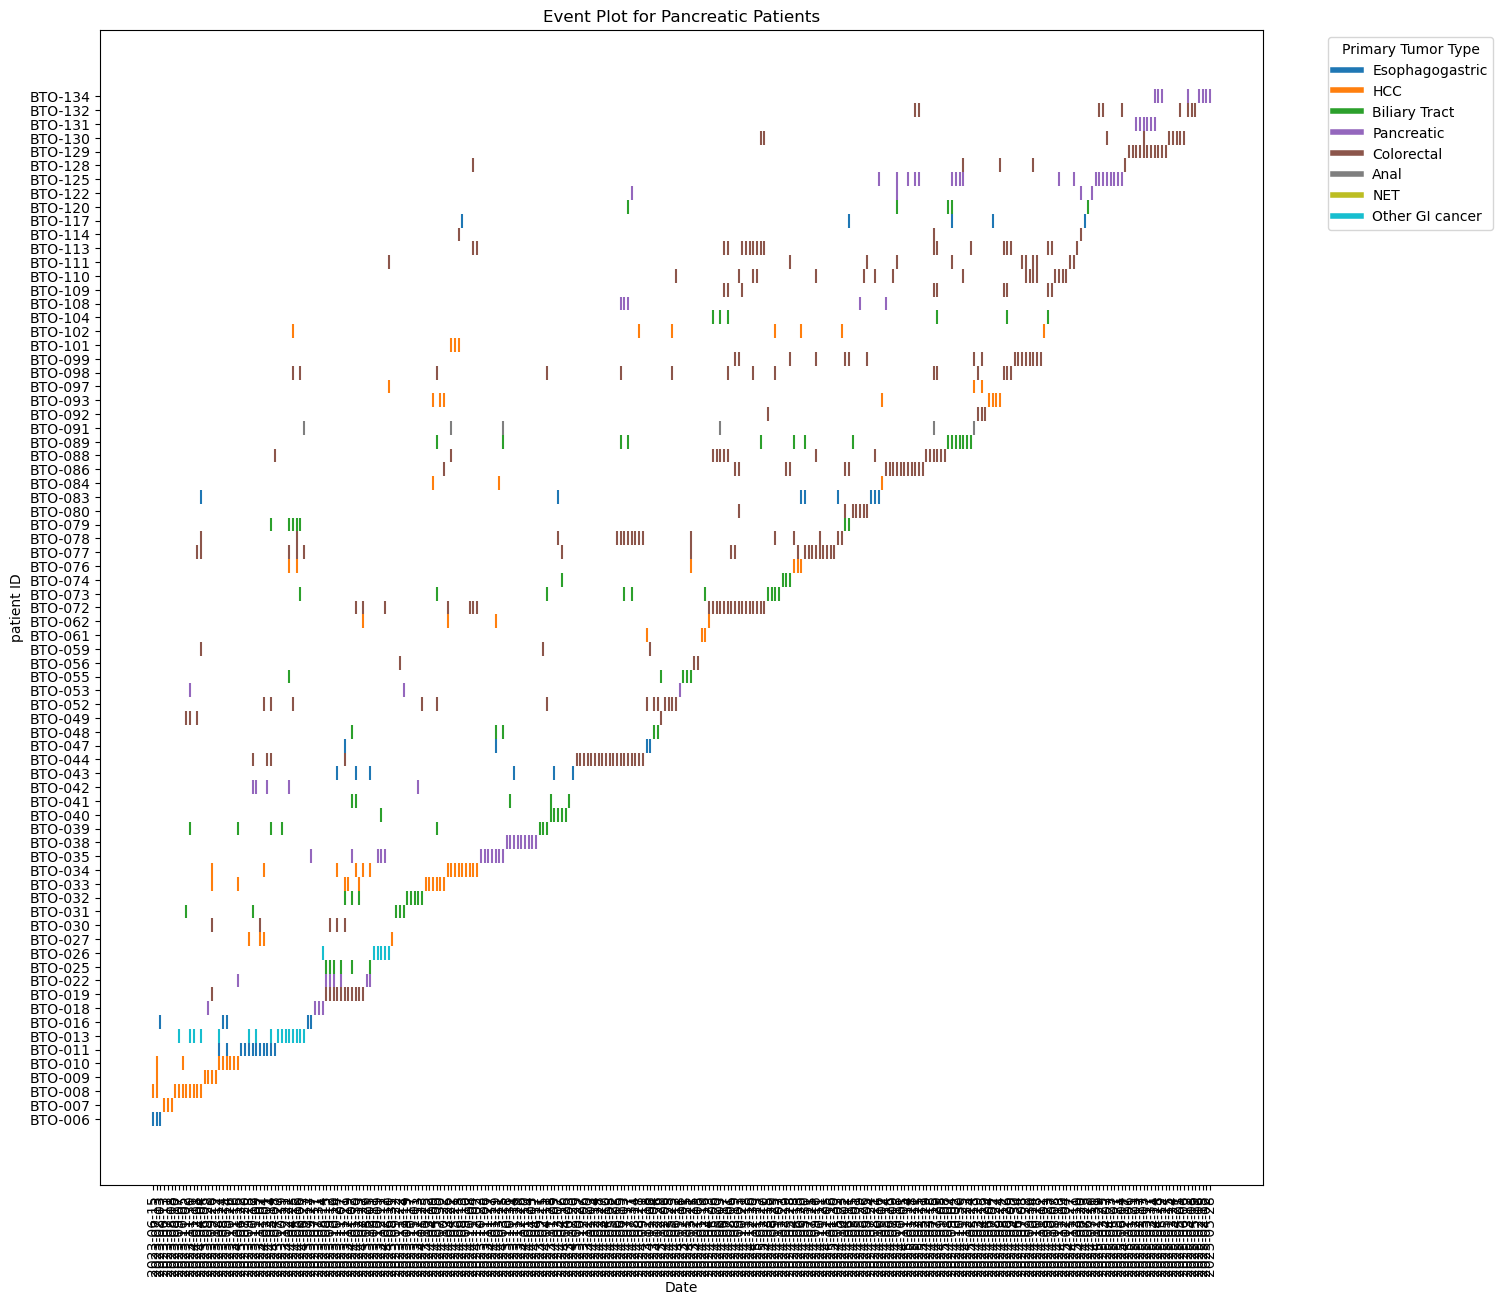

In [10]:
eventplot_data = {ptID: NSRdict[ptID]['collection_date'].values.flatten() for ptID in ptList}
#color map for 8
cmap = plt.cm.get_cmap('tab10', 8)
#cmap each primary tumor type to a color
color_dict = {ptID: cmap(tumortypeDict[ptID] - 1) for ptID in tumortypeDict}
fig, ax = plt.subplots(figsize=(15, 15))
ax.eventplot(eventplot_data.values(), lineoffsets =1, colors=[color_dict[ptID] for ptID in eventplot_data.keys()])
ax.set_title('Event Plot for Pancreatic Patients')
ax.set_xlabel('Date')
ax.set_ylabel('patient ID')
#make the x-axis labels vertical
ax.tick_params(axis='x', rotation=90)
yaxislabels = [ptID for ptID in eventplot_data.keys()]
ax.set_yticks(np.arange(0, len(yaxislabels), 1), yaxislabels, rotation = 'horizontal')
#key for colors
handles = [plt.Line2D([0], [0], color=cmap(i), lw=4) for i in range(8)]
labels = ['Esophagogastric', 'HCC', 'Biliary Tract', 'Pancreatic', 'Colorectal', 'Anal', 'NET', 'Other GI cancer']
ax.legend(handles, labels, title='Primary Tumor Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

# code below this point needed updated and corrected

Code below this point need updated

## managing metastasis information

this needs updated to handle alignment problems

In [9]:
metsLongDict = {}
for ptID in metEnrollmentDict.keys():
    mets = metEnrollmentDict[ptID]
    if len(mets) > 0:
        mets_new = [x if x in mets else 0 for x in range(1,7)]
    elif len(mets) == 0:
        mets_new = [0 for x in range(1,7)]
    metsLongDict[ptID] = mets_new

metsLongDict        

{'BTO-018': [0, 2, 0, 0, 0, 0],
 'BTO-022': [1, 0, 0, 0, 0, 0],
 'BTO-035': [0, 0, 0, 0, 5, 0],
 'BTO-038': [1, 0, 0, 0, 0, 0],
 'BTO-042': [1, 0, 0, 0, 0, 0],
 'BTO-053': [0, 2, 3, 0, 0, 6],
 'BTO-082': [1, 0, 0, 0, 0, 0],
 'BTO-108': [1, 0, 3, 0, 5, 0],
 'BTO-121': [1, 0, 0, 4, 5, 0],
 'BTO-122': [1, 2, 0, 4, 5, 0],
 'BTO-125': [0, 2, 0, 0, 0, 0],
 'BTO-131': [1, 2, 0, 4, 5, 0],
 'BTO-134': [1, 0, 0, 0, 0, 0]}

In [10]:
for ptID in NSRdict:
    print(ptID, len(NSRdict[ptID]))

BTO-018 4
BTO-022 7
BTO-035 12
BTO-038 9
BTO-042 5
BTO-053 3
BTO-082 1
BTO-108 5
BTO-121 2
BTO-122 4
BTO-125 19
BTO-131 6
BTO-134 8


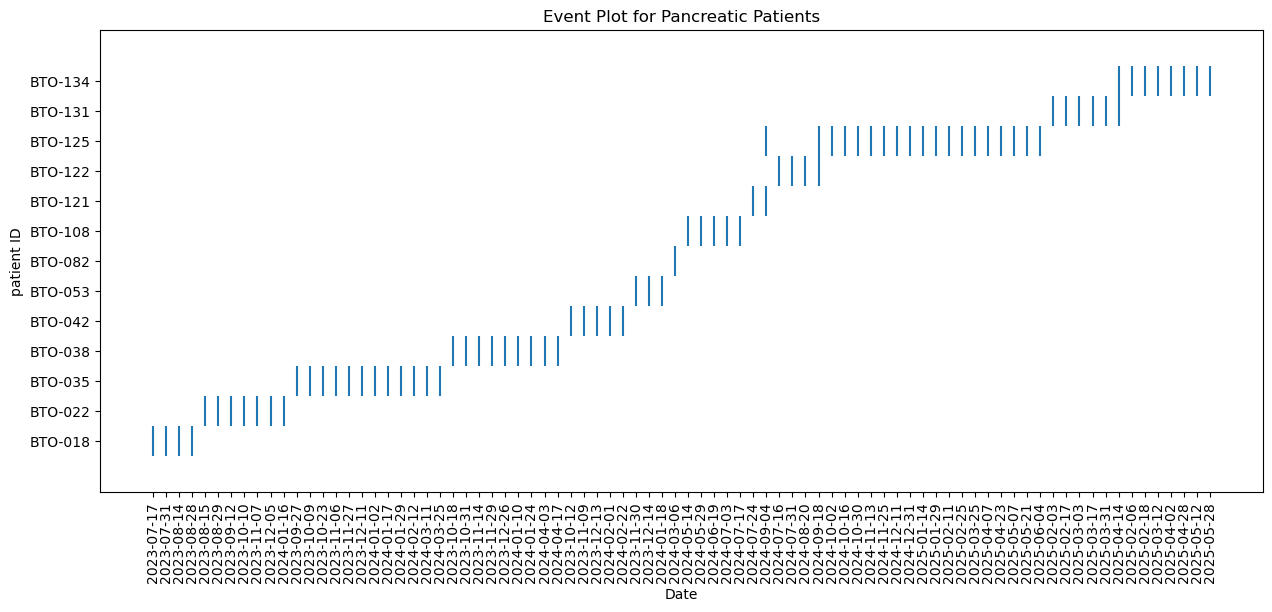

In [11]:
eventplot_data = {ptID: NSRdict[ptID]['collection_date'].values.flatten() for ptID in NSRdict}
fig, ax = plt.subplots(figsize=(15, 6))
ax.eventplot(eventplot_data.values(), lineoffsets =1)
ax.set_title('Event Plot for Pancreatic Patients')
ax.set_xlabel('Date')
ax.set_ylabel('patient ID')
#make the x-axis labels vertical
ax.tick_params(axis='x', rotation=90)
yaxislabels = [ptID for ptID in eventplot_data.keys()]
ax.set_yticks(np.arange(0, len(yaxislabels), 1), yaxislabels, rotation = 'horizontal')
plt.show()

In [12]:
methylationDict

{'BTO-018':      Unnamed: 0  10_q24.2_1  8_q21.3_1  1_p13.3_1  10_q22.1_1  11_q25_1  \
 0  NS1035CR0041           0   0.550604          0           0         0   
 1  NS1035CR0009           0   0.000000          0           0         0   
 2  NS1035CR0015           0   0.000000          0           0         0   
 3  NS1035CR0024           0   0.000000          0           0         0   
 
    12_q24.33_1  15_q21.1_1  15_q26.3_1  16_p13.3_2  ...  8_q24.22_12  \
 0            0           0    0.000000    0.000000  ...     0.028705   
 1            0           0   -0.003756   -0.002179  ...     0.499043   
 2            0           0   -0.004043    0.000000  ...    -0.002143   
 3            0           0    0.000000    0.000000  ...    -0.002964   
 
    21_q22.11_7  7_q21.3_29  10_q26.13_9  12_q24.33_12  6_p12.1_21  \
 0    -0.003141   -0.002586    -0.002587      0.912286    0.394521   
 1     0.383062    0.059753     0.378184      0.605995    1.311740   
 2    -0.002091   -0.002346   

# fits

In [28]:
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import mean_squared_error, r2_score
from scipy.optimize import curve_fit

In [ ]:
#define a function for the quadratic model 
def quadratic_model(x, a, b, c):
    return a * x**2 + b * x + c

#define a function for the exponetial model
def exponential_model(x, a, b, c):
    return a * np.exp(b * x) + c


#may want to rename labels below for easier access

def quadratic_fit(x_data, y_data):
    # Fit the quadratic model to the data
    popt, pcov = curve_fit(quadratic_model, x_data, y_data)
    return popt  # Returns the optimal parameters a, b, c

def exponential_fit(x_data, y_data):
    # Fit the exponential model to the data
    popt, pcov = curve_fit(exponential_model, x_data, y_data)
    return popt  # Returns the optimal parameters a, b, c

In [ ]:
#collect what you need for the TMS per patient to perform fits
#use the code below to help with the elapsed time


In [51]:
#linear fit of the methylation pattern per patient per locus

pancPtsFitsDict_Linear = {}
pancPtsFitsDict_Linear_predicts = {}
for ptID in methylationDict.keys():
    # ptData = ptfn.patientSectionOfFrame(methylationPatternsAll, 'ptID', ptID=ptID)
    ptData = methylationPatternsAll[methylationPatternsAll['ptID'] == ptID]
    ptData['date'] = pd.to_datetime(ptData['date'])
    startTime = ptData['date'][0]
    ptData['elapsedTime'] = (ptData['date']-startTime).dt.days
    # ptFitsDict = {}
    ptPredicts = {}
    i = 0
    for col in methylationPatternsAll_clean.columns:
        
        x_values, y_values, datalength, baseline = ptfn.prepDataForFit_methyl(ptData, time = 'elapsedTime',  dataColumn= col)
        coef, intercept, mse, r2, y_prediction = ptfn.linear_model_fit_v2(x_values, y_values, datalength, baseline, forced = False)
        if i == 0: 
            ptFits = pd.DataFrame({col + "__lin_coef": [coef],
                                   col+"__lin_intercept": [intercept],
                                   col + "__lin_mse": [mse],
                                   col+"__lin_r2": [r2]})
        else: 
            ptFits = pd.concat([ptFits, pd.DataFrame({col + "__lin_coef": [coef],
                                   col+"__lin_intercept": [intercept],
                                   col + "__lin_mse": [mse],
                                   col+"__lin_r2": [r2]})], axis = 1)
        # ptFitsDict[col] = [coef, intercept, mse, r2]
        ptPredicts[col] = [y_prediction]
        i +=1

    pancPtsFitsDict_Linear[ptID] = ptFits
    pancPtsFitsDict_Linear_predicts[ptID] = ptPredicts

C:\Users\maega\AppData\Local\Temp\ipykernel_30144\4264133515.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ptData['date'] = pd.to_datetime(ptData['date'])
C:\Users\maega\AppData\Local\Temp\ipykernel_30144\4264133515.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ptData['elapsedTime'] = (ptData['date']-startTime).dt.days
C:\Users\maega\AppData\Local\Temp\ipykernel_30144\4264133515.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,co

In [75]:
pancPtsFitsDict_Linear_df = pd.concat(pancPtsFitsDict_Linear.values(), axis=0, ignore_index=False)
pancPtsFitsDict_Linear_df.index = pancPtsFitsDict_Linear.keys()
pancPtsFitsDict_Linear_df

,10_q24.2_1__lin_coef,10_q24.2_1__lin_intercept,10_q24.2_1__lin_mse,10_q24.2_1__lin_r2,8_q21.3_1__lin_coef,8_q21.3_1__lin_intercept,8_q21.3_1__lin_mse,8_q21.3_1__lin_r2,1_p13.3_1__lin_coef,1_p13.3_1__lin_intercept,...,17_p11.2_20__lin_mse,17_p11.2_20__lin_r2,2_q14.2_22__lin_coef,2_q14.2_22__lin_intercept,2_q14.2_22__lin_mse,2_q14.2_22__lin_r2,2_q31.1_39__lin_coef,2_q31.1_39__lin_intercept,2_q31.1_39__lin_mse,2_q31.1_39__lin_r2
BTO-018,0.000000e+00,0.000000,0.000000e+00,1.000000,-0.011799,0.385423,2.273734e-02,0.600000,0.000000,0.000000,...,2.424518e-03,0.551826,-0.001917,0.055295,6.803604e-04,0.569503,-0.010168,0.330524,1.711956e-02,0.596698
BTO-022,2.016333e-06,-0.000805,2.726675e-06,0.003980,0.139698,0.332013,1.428565e+02,0.267995,-0.006795,3.247939,...,4.830359e-01,0.084223,-0.004145,0.849798,2.507014e-01,0.155143,0.045581,-0.325065,1.087710e+01,0.338579
BTO-035,1.284055e-05,-0.002309,2.319357e-06,0.191098,-0.000321,0.183782,2.534621e-01,0.001353,-0.001797,0.219433,...,1.073363e-02,0.254203,-0.003771,0.530842,9.599195e-02,0.329879,-0.002028,0.323821,2.512294e-01,0.051616
BTO-038,-1.255773e-07,-0.002190,6.166543e-06,0.000010,0.000012,-0.002477,4.724554e-06,0.106300,-0.006670,1.244520,...,1.281088e-01,0.266393,-0.000795,0.451605,4.177143e-01,0.005622,-0.000553,0.085838,1.279805e-02,0.081914
BTO-042,0.000000e+00,0.000000,0.000000e+00,1.000000,0.010458,-0.307201,3.476765e-01,0.438547,0.000000,0.000000,...,7.093725e-03,0.467237,-0.007073,0.793067,2.367979e-01,0.344109,-0.000244,0.022521,1.842901e-04,0.445725
BTO-053,0.000000e+00,0.000000,0.000000e+00,1.000000,0.000000,0.000000,0.000000e+00,1.000000,0.000016,-0.000679,...,8.251098e-04,0.465539,0.021604,-0.211773,2.576104e-02,0.884977,-0.004450,0.178298,7.429805e-03,0.530955
BTO-082,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,...,-3.498587e-06,0.000000,0.000000,-0.164914,-1.649141e-01,0.000000,0.000000,-0.001981,-1.980759e-03,0.000000
BTO-108,-4.505814e-05,-0.001313,4.247027e-06,0.203481,0.000090,-0.005734,8.647503e-07,0.834762,-0.005715,0.485642,...,7.210987e-02,0.065413,0.000142,-0.058348,1.879094e-02,0.000569,0.012150,-0.130699,2.572382e-02,0.754108
BTO-121,0.000000e+00,0.000000,0.000000e+00,1.000000,0.000000,0.000000,0.000000e+00,1.000000,0.000000,0.000000,...,2.445028e-35,1.000000,-0.020265,0.851129,6.164764e-33,1.000000,0.009123,-0.005495,2.542829e-34,1.000000
BTO-122,3.062723e-05,-0.001490,6.038190e-07,0.471485,0.000000,0.000000,0.000000e+00,1.000000,-0.020871,1.434411,...,4.612769e-02,0.846726,-0.004151,0.297561,8.243335e-02,0.107160,0.000222,0.011293,9.989259e-04,0.027647


# mets

In [96]:
y_train_mets = pd.DataFrame([metsLongDict[x] for x in pancPtsFitsDict_Linear_df.index])
# y_train_mets
y_train_mets.index = pancPtsFitsDict_Linear_df.index

y_train_mets.columns = ['met_1', 'met_2', 'met_3', 'met_4', 'met_5', 'met_6']
y_train_mets

,met_1,met_2,met_3,met_4,met_5,met_6
BTO-018,0,2,0,0,0,0
BTO-022,1,0,0,0,0,0
BTO-035,0,0,0,0,5,0
BTO-038,1,0,0,0,0,0
BTO-042,1,0,0,0,0,0
BTO-053,0,2,3,0,0,6
BTO-082,1,0,0,0,0,0
BTO-108,1,0,3,0,5,0
BTO-121,1,0,0,4,5,0
BTO-122,1,2,0,4,5,0
